In [1]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from xgboost import XGBClassifier

In [17]:
import pandas as pd
import numpy as np

raw_data = pd.read_csv("industrial-machine-condition-classification/student_dataset.csv")
test_df = pd.read_csv("industrial-machine-condition-classification/test.csv")

raw_data.head()

,unit_id,unit_type,ambient_temp,process_temp,coolant_flow,shaft_speed,drive_torque,power_load,component_wear,thermal_stress,mechanical_load,vibration_index,condition
0,UNT-184174,M,21.5,56.4,17.85,1454.0,58.2,9.099,30.0,29.31,57.19,1.768,0
1,UNT-236234,H,29.9,65.0,30.88,1720.0,54.6,10.101,13.0,23.93,36.94,1.081,0
2,UNT-247460,M,26.4,47.8,19.75,1552.0,38.4,6.328,89.0,13.52,38.22,1.031,0
3,UNT-176316,M,28.8,60.9,19.10,1513.0,49.1,7.768,59.0,24.62,46.17,1.011,0
4,UNT-105110,S,29.4,64.0,11.77,1536.0,52.6,8.405,36.0,27.83,94.72,1.851,1


In [4]:
X = raw_data.drop(columns=["unit_id", "condition"])
y = raw_data["condition"]

In [5]:
cat_cols = ["unit_type"]
num_cols = X.select_dtypes(include="number").columns.to_list()

num_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

cat_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", num_pipeline, num_cols),
    ("cat", cat_pipeline, cat_cols)
])

In [6]:
skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [7]:
baseline_model = XGBClassifier(
    random_state=42,
    eval_metric="mlogloss",
    n_jobs=4
)

baseline_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", baseline_model)
])

baseline_results = cross_validate(
    baseline_pipeline,
    X,
    y,
    cv=skf,
    scoring="accuracy",
    return_train_score=True,
    n_jobs=1
)

print("Train Accuracy:",
      baseline_results["train_score"].mean())

print("Validation Accuracy:",
      baseline_results["test_score"].mean())

print("Validation Std:",
      baseline_results["test_score"].std())

Train Accuracy: 0.9815625000000001
Validation Accuracy: 0.8814375
Validation Std: 0.004101257429130749


In [11]:
def objective(trial):

    params = {
        "n_estimators": trial.suggest_int(
            "n_estimators", 100, 250
        ),
        "learning_rate": trial.suggest_float(
            "learning_rate", 0.01, 0.2, log=True
        ),
        "max_depth": trial.suggest_int(
            "max_depth", 2, 6
        ),
        "min_child_weight": trial.suggest_int(
            "min_child_weight", 1, 9
        ),
        "gamma": trial.suggest_float(
            "gamma", 0.0, 5.0
        ),
        "subsample": trial.suggest_float(
            "subsample", 0.6, 1.0
        ),
        "colsample_bytree": trial.suggest_float(
            "colsample_bytree", 0.6, 1.0
        ),
        "reg_alpha": trial.suggest_float(
            "reg_alpha", 0.0, 3.0
        ),
        "reg_lambda": trial.suggest_float(
            "reg_lambda", 3, 9.0
        )
    }

    model = XGBClassifier(
        **params,
        objective="multi:softprob",
        num_class=3,
        eval_metric="mlogloss",
        random_state=42,
        tree_method="hist",
        n_jobs=4
    )

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    results = cross_validate(
        pipeline,
        X,
        y,
        cv=skf,
        scoring="accuracy",
        return_train_score=True,
        n_jobs=1
    )

    train_mean = results["train_score"].mean()
    val_mean = results["test_score"].mean()
    val_std = results["test_score"].std()

    trial.set_user_attr("train_accuracy", train_mean)
    trial.set_user_attr("validation_std", val_std)
    trial.set_user_attr("gap", train_mean - val_mean)

    return val_mean

import optuna


study = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(seed=42)
)

study.optimize(
    objective,
    n_trials=50
)

[I 2026-10-09 15:25:14,270] A new study created in memory with name: no-name-db990ea4-211b-458d-a563-ef9073267be5
[I 2026-10-09 15:25:15,539] Trial 0 finished with value: 0.884375 and parameters: {'n_estimators': 156, 'learning_rate': 0.17254716573280354, 'max_depth': 5, 'min_child_weight': 6, 'gamma': 0.7800932022121826, 'subsample': 0.662397808134481, 'colsample_bytree': 0.6232334448672797, 'reg_alpha': 2.5985284373248057, 'reg_lambda': 6.606690070459253}. Best is trial 0 with value: 0.884375.
[I 2026-10-09 15:25:17,694] Trial 1 finished with value: 0.871875 and parameters: {'n_estimators': 206, 'learning_rate': 0.010636066512540286, 'max_depth': 6, 'min_child_weight': 8, 'gamma': 1.0616955533913808, 'subsample': 0.6727299868828402, 'colsample_bytree': 0.6733618039413735, 'reg_alpha': 0.9127267288786132, 'reg_lambda': 6.148538589793427}. Best is trial 0 with value: 0.884375.
[I 2026-10-09 15:25:19,232] Trial 2 finished with value: 0.875625 and parameters: {'n_estimators': 165, 'learn

In [12]:
best_params = study.best_params

best_model = XGBClassifier(
    **best_params,
    objective="multi:softprob",
    num_class=3,
    eval_metric="mlogloss",
    tree_method="hist",
    random_state=42,
    n_jobs=4
)

best_pipeline = Pipeline([
    ("preprocessor",preprocessor),
    ("model",best_model)
])

In [13]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    accuracy_score
)

oof_preds = cross_val_predict(
    best_pipeline,
    X,
    y,
    cv=skf,
    method="predict",
    n_jobs=1
)

print("OOF Accuracy:", accuracy_score(y, oof_preds))

OOF Accuracy: 0.8850625


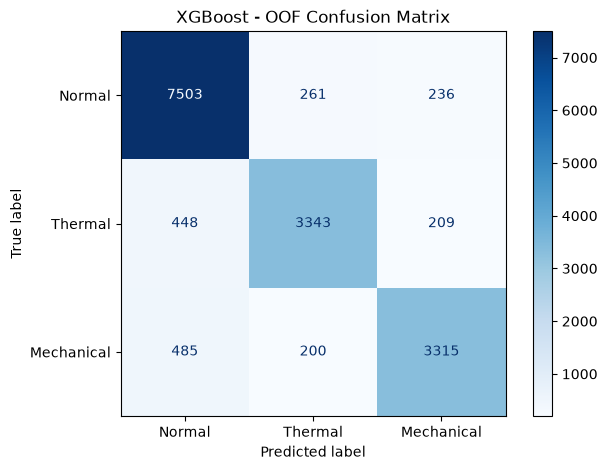

In [14]:
import matplotlib.pyplot as plt

cm = confusion_matrix(
    y,
    oof_preds,
    labels=[0, 1, 2]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[
        "Normal",
        "Thermal",
        "Mechanical"
    ]
)

fig, ax = plt.subplots(figsize=(7, 5))
disp.plot(ax=ax, cmap="Blues", values_format="d")
plt.title("XGBoost - OOF Confusion Matrix")
plt.show()

In [15]:
print(
    classification_report(
        y,
        oof_preds,
        labels=[0, 1, 2],
        target_names=[
            "Normal",
            "Thermal Failure",
            "Mechanical Failure"
        ],
        digits=4
    )
)

                    precision    recall  f1-score   support

            Normal     0.8894    0.9379    0.9130      8000
   Thermal Failure     0.8788    0.8357    0.8567      4000
Mechanical Failure     0.8816    0.8287    0.8544      4000

          accuracy                         0.8851     16000
         macro avg     0.8833    0.8675    0.8747     16000
      weighted avg     0.8848    0.8851    0.8843     16000



In [16]:
best_pipeline.fit(X, y)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](3,)","[0,1,2]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](11,)","['unit_type','ambient_temp','process_temp',...,'thermal_stress', 'mechanical_load','vibration_index']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,11
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying `

In [18]:
X_test = test_df.drop(columns=["unit_id"])

predictions = best_pipeline.predict(X_test)

In [19]:
submission = pd.DataFrame({
    "unit_id": test_df["unit_id"],
    "condition": predictions
})

submission.to_csv("submission.csv", index=False)

print(submission.head())
print(submission["condition"].value_counts())

      unit_id  condition
0  UNT-184630          0
1  UNT-228473          0
2  UNT-255783          1
3  UNT-119059          2
4  UNT-205559          0
condition
0    2115
1     947
2     938
Name: count, dtype: int64


In [20]:
import joblib

joblib.dump(best_pipeline, "machine_model.joblib")

['machine_model.joblib']